# 01 · RePaint baseline benchmark (fixed resampling schedule)

**Reference:** Lugmayr et al., *RePaint: Inpainting Using Denoising Diffusion Probabilistic Models*, CVPR 2022 ([paper](https://openaccess.thecvf.com/content/CVPR2022/html/Lugmayr_RePaint_Inpainting_Using_Denoising_Diffusion_Probabilistic_Models_CVPR_2022_paper.html), [official code](https://github.com/andreas128/RePaint)).

This notebook runs the project's verified fixed-schedule sampler, `src.repaint.repaint_pipeline`, with the settings in `configs/config.yaml` (T = 250, jump length 10, jump_n_sample 10, i.e. 2,410 denoiser calls per image). It imports the project modules; the sampler is **not** re-implemented here.

**Model limitation.** The project uses the Hugging Face checkpoint `google/ddpm-celebahq-256` (3-channel ε-prediction, fixed posterior variance). The paper used the authors' own CelebA-HQ guided-diffusion checkpoint with learned variance. This is therefore a *RePaint-style implementation adapted to that checkpoint*, not a checkpoint-level reproduction of the paper's numbers.

**Run order**
1. Setup cells (§0).
2. Smoke test A: no checkpoint, a fake denoiser that checks the schedule and the call count (seconds).
3. Smoke test B: the real checkpoint on one image with a *reduced* schedule (about 140 calls).
4. §3 Full baseline: only runs if you set `RUN_FULL_BASELINE = True`. On a T4, expect roughly 2,410 UNet calls per image.

## 0 · Setup

In [1]:
import os
import sys
from pathlib import Path

def _find_project_root():
    env = os.environ.get("REPAINT_PROJECT_ROOT")
    candidates = ([Path(env).expanduser()] if env else []) + [Path.cwd(), *Path.cwd().resolve().parents]
    for candidate in candidates:
        if (candidate / "src" / "repaint.py").is_file() and (candidate / "configs" / "config.yaml").is_file():
            return candidate.resolve()
    raise FileNotFoundError(
        "Could not find the project root (needs src/repaint.py and configs/config.yaml). "
        "Start Jupyter inside the repository or set REPAINT_PROJECT_ROOT. Searched: "
        + ", ".join(map(str, candidates)))

PROJECT_ROOT = _find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: /home/sarthak/programs/budget/Generative_Image_Impainting


In [2]:
import platform
import importlib
import torch

print("Python      :", platform.python_version())
print("PyTorch     :", torch.__version__, "| CUDA build:", torch.version.cuda)
print("CUDA usable :", torch.cuda.is_available())
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        p = torch.cuda.get_device_properties(i)
        print(f"  GPU {i}: {p.name}, {p.total_memory / 2**30:.1f} GiB")
for name in ("diffusers", "torchvision", "torchmetrics", "matplotlib", "pandas", "yaml", "lpips"):
    try:
        module = importlib.import_module(name)
        print(f"{name:12s}:", getattr(module, "__version__", "installed"))
    except ImportError:
        print(f"{name:12s}: NOT INSTALLED" + ("" if name in ("torchmetrics", "lpips") else "  <-- required"))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device      :", DEVICE)

Python      : 3.10.20
PyTorch     : 2.14.0+cu130 | CUDA build: 13.0
CUDA usable : True
  GPU 0: NVIDIA GeForce RTX 3050 Laptop GPU, 3.7 GiB


/home/sarthak/miniconda3/envs/repaint/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


diffusers   : 0.40.0
torchvision : 0.29.0+cu130
torchmetrics: 1.9.0
matplotlib  : 3.10.9
pandas      : 2.3.3
yaml        : 6.0.3
lpips       : NOT INSTALLED
Device      : cuda


In [3]:
from src.config import load_project_config, resolve_project_path

CONFIG_PATH = resolve_project_path("configs/config.yaml", PROJECT_ROOT, must_exist=True)
CFG = load_project_config(project_root=PROJECT_ROOT)
RCFG = CFG["repaint"]
ECFG = CFG.get("experiment", {})
MODEL_ID = CFG["model"]["pretrained_model_name"]
IMAGE_SIZE = int(CFG["data"]["image_size"])
T_STEPS = int(RCFG["num_inference_steps"])
JUMP_LENGTH = int(RCFG["jump_length"])
JUMP_N_SAMPLE = int(RCFG["jump_n_sample"])
MASK_RATIO = float(RCFG["mask_ratio"])
DATA_DIR = resolve_project_path(ECFG.get("data_dir", "data/celeba"), PROJECT_ROOT)
RESULTS_ROOT = resolve_project_path(ECFG.get("results_dir", "results_benchmarks"), PROJECT_ROOT)
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".webp", ".bmp"}

def list_images(data_dir):
    if not data_dir.exists():
        return []
    return sorted((p for p in data_dir.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS),
                  key=lambda p: str(p).lower())

print("Config      :", CONFIG_PATH)
print("Model       :", MODEL_ID, "(Hugging Face id; downloaded on first load if not cached)")
print(f"RePaint     : T={T_STEPS}, jump_length={JUMP_LENGTH}, jump_n_sample={JUMP_N_SAMPLE}, mask_ratio={MASK_RATIO}")
print("Data dir    :", DATA_DIR, "| images found:", len(list_images(DATA_DIR)))
print("Results dir :", RESULTS_ROOT)
if not list_images(DATA_DIR):
    print("No images yet. Run `python scripts/download_celeba_sample.py` from the project root "
          "(needs the `datasets` package and internet), or put images in", DATA_DIR)

Config      : /home/sarthak/programs/budget/Generative_Image_Impainting/configs/config.yaml
Model       : google/ddpm-celebahq-256 (Hugging Face id; downloaded on first load if not cached)
RePaint     : T=250, jump_length=10, jump_n_sample=10, mask_ratio=0.35
Data dir    : /home/sarthak/programs/budget/Generative_Image_Impainting/data/celeba | images found: 20
Results dir : /home/sarthak/programs/budget/Generative_Image_Impainting/results_benchmarks


In [4]:
import random
import numpy as np

SEED = int(RCFG["seed"])
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("Base seed:", SEED, "| per-image generator seed = SEED + image index")

Base seed: 42 | per-image generator seed = SEED + image index


## 1 · Smoke test A — schedule and call count (no checkpoint)

In [5]:
# Test doubles for smoke tests that need no checkpoint or dataset.
# They only exercise the control flow, NFE accounting and file output; their
# images are meaningless.
from types import SimpleNamespace

class FakeScheduler:
    def __init__(self, num_train_timesteps=1000):
        self.betas = torch.linspace(1e-4, 0.02, num_train_timesteps)
        self.alphas_cumprod = torch.cumprod(1.0 - self.betas, dim=0)
        self.config = SimpleNamespace(num_train_timesteps=num_train_timesteps,
                                      prediction_type="epsilon", clip_sample=True)

class FakeDenoiser:
    def __call__(self, sample, timesteps):
        t = timesteps.to(sample.dtype).view(-1, 1, 1, 1) / 1000.0
        return SimpleNamespace(sample=0.5 * torch.tanh(sample) + 0.1 * t * sample.roll(1, dims=-1))

def synthetic_image(size, seed=0):
    g = torch.Generator().manual_seed(seed)
    yy, xx = torch.meshgrid(torch.linspace(-1, 1, size), torch.linspace(-1, 1, size), indexing="ij")
    base = torch.stack([xx, yy, xx * yy]) * 0.8
    return (base + 0.05 * torch.randn(3, size, size, generator=g)).clamp(-1, 1).unsqueeze(0)

In [6]:
from src.repaint import build_repaint_schedule, count_schedule_transitions, repaint_pipeline
from src.adaptive_repaint import CountingModel

schedule = build_repaint_schedule(T_STEPS, JUMP_LENGTH, JUMP_N_SAMPLE)
reverse_calls, forward_steps = count_schedule_transitions(schedule)
print(f"Schedule entries: {len(schedule)} | reverse (model) calls: {reverse_calls} | forward noising steps: {forward_steps}")

counter = CountingModel(FakeDenoiser())
x_fake = synthetic_image(16)
m_fake = torch.zeros(1, 1, 16, 16); m_fake[..., 4:12, 4:12] = 1.0
out = repaint_pipeline(counter, FakeScheduler(), x_fake, m_fake, JUMP_LENGTH, JUMP_N_SAMPLE,
                       generator=torch.Generator().manual_seed(SEED), num_inference_steps=T_STEPS)
assert counter.evaluations == reverse_calls, (counter.evaluations, reverse_calls)
assert out.shape == x_fake.shape and torch.isfinite(out).all()
print(f"Measured denoiser calls with the fake model: {counter.evaluations}  ✓ equals the schedule count")

Schedule entries: 4571 | reverse (model) calls: 2410 | forward noising steps: 2160
Measured denoiser calls with the fake model: 2410  ✓ equals the schedule count


## 2 · Smoke test B — real checkpoint, one image, reduced schedule

Downloads/loads `google/ddpm-celebahq-256` with the project loader and runs T = 50, j = 5, r = 3 (140 calls). This checks the real model end to end; the reduced schedule is **not** the benchmark setting, so do not read quality conclusions from it.

/home/sarthak/miniconda3/envs/repaint/lib/python3.10/site-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
An error occurred while trying to fetch google/ddpm-celebahq-256: google/ddpm-celebahq-256 does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Scheduler: {'num_train_timesteps': 1000, 'beta_schedule': 'linear', 'variance_type': 'fixed_small', 'prediction_type': 'epsilon', 'clip_sample': True}
Image: celeba_000.png | NFE 140 (expected 140) | 18.4 s
{'missing_fraction': 0.1209, 'composite_full_psnr_db': 27.9402, 'composite_full_ssim': 0.9407, 'composite_full_mse': 0.0016, 'missing_mse': 0.0133, 'missing_mae': 0.0744, 'missing_psnr_db': 18.7632, 'boundary_width_px': 8.0, 'boundary_inner_mse': 0.0104, 'boundary_inner_mae': 0.0572, 'boundary_inner_psnr_db': 19.8212, 'raw_full_psnr_db': 27.878, 'raw_full_ssim': 0.9323, 'raw_known_mse': 0.0, 'raw_known_mae': 0.0037, 'raw_known_psnr_db': 45.7888, 'raw_known_max_abs_error': 0.0771, 'lpips_composite': None}


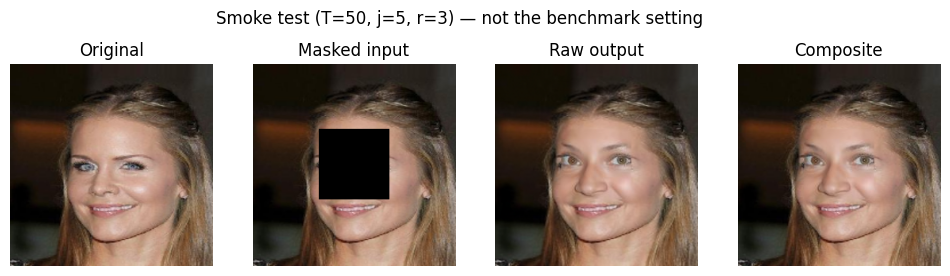

In [7]:
RUN_REAL_MODEL_SMOKE = True   # set False if the checkpoint or data are not available yet
SMOKE = dict(num_inference_steps=50, jump_length=5, jump_n_sample=3)

import time
from src.dataset import load_image, tensor_to_pil
from src.mask import create_center_mask
from src.metrics import compute_inpainting_metrics
from src.model import load_pretrained_ddpm

MODEL = SCHEDULER = None
if RUN_REAL_MODEL_SMOKE:
    images = list_images(DATA_DIR)
    if not images:
        raise FileNotFoundError(f"No images under {DATA_DIR}. See the message printed in §0.")
    MODEL, SCHEDULER, DEVICE = load_pretrained_ddpm(MODEL_ID, device=DEVICE)
    print("Scheduler:", {k: SCHEDULER.config[k] for k in ("num_train_timesteps", "beta_schedule", "variance_type", "prediction_type", "clip_sample")})
    x0 = load_image(str(images[0]), IMAGE_SIZE).to(DEVICE)
    mask = create_center_mask(IMAGE_SIZE, MASK_RATIO).to(DEVICE)
    counter = CountingModel(MODEL)
    t0 = time.perf_counter()
    raw = repaint_pipeline(counter, SCHEDULER, x0, mask, SMOKE["jump_length"], SMOKE["jump_n_sample"],
                           generator=torch.Generator(device=DEVICE).manual_seed(SEED),
                           num_inference_steps=SMOKE["num_inference_steps"])
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0
    expected = count_schedule_transitions(build_repaint_schedule(**SMOKE))[0]
    assert counter.evaluations == expected
    m = compute_inpainting_metrics(raw, x0, mask)
    print(f"Image: {images[0].name} | NFE {counter.evaluations} (expected {expected}) | {elapsed:.1f} s")
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in m.items()})
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 4, figsize=(12, 3.2))
    for a, (title, img) in zip(ax, [("Original", x0), ("Masked input", x0 * (1 - mask) - mask),
                                    ("Raw output", raw), ("Composite", (1 - mask) * x0 + mask * raw)]):
        a.imshow(tensor_to_pil(img)); a.set_title(title); a.axis("off")
    fig.suptitle(f"Smoke test (T={SMOKE['num_inference_steps']}, j={SMOKE['jump_length']}, r={SMOKE['jump_n_sample']}) — not the benchmark setting")
    plt.show()
else:
    print("Real-model smoke test skipped.")

## 3 · Full baseline (explicit opt-in)

Runs the paper schedule from `configs/config.yaml` on the first `evaluation.max_images` images with the centre mask, using the same seed convention as `scripts/run_batch.py`. It saves raw outputs, composites, per-image metrics (CSV), and the exact run configuration (JSON) to `results_benchmarks/baseline_notebook/`. Raw-sampler metrics and composite metrics are reported separately.

In [8]:
RUN_FULL_BASELINE = True   # set True deliberately; ~2,410 UNet calls per image

import csv, json
from src.experiment_io import environment_info, save_mask_png

BASELINE_DIR = RESULTS_ROOT / "baseline_notebook" / f"seed{SEED}_T{T_STEPS}_j{JUMP_LENGTH}_r{JUMP_N_SAMPLE}_mask{MASK_RATIO:g}"
if RUN_FULL_BASELINE:
    images = list_images(DATA_DIR)
    max_images = CFG.get("evaluation", {}).get("max_images")
    images = images[: int(max_images)] if max_images is not None else images
    if not images:
        raise FileNotFoundError(f"No images under {DATA_DIR}")
    if MODEL is None:
        MODEL, SCHEDULER, DEVICE = load_pretrained_ddpm(MODEL_ID, device=DEVICE)
    mask = create_center_mask(IMAGE_SIZE, MASK_RATIO).to(DEVICE)
    (BASELINE_DIR / "images").mkdir(parents=True, exist_ok=True)
    save_mask_png(mask, BASELINE_DIR / "images" / "mask_missing_white.png")
    expected = count_schedule_transitions(build_repaint_schedule(T_STEPS, JUMP_LENGTH, JUMP_N_SAMPLE))[0]
    rows = []
    for index, path in enumerate(images):
        x0 = load_image(str(path), IMAGE_SIZE).to(DEVICE)
        counter = CountingModel(MODEL)
        if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
        t0 = time.perf_counter()
        raw = repaint_pipeline(counter, SCHEDULER, x0, mask, JUMP_LENGTH, JUMP_N_SAMPLE,
                               generator=torch.Generator(device=DEVICE).manual_seed(SEED + index),
                               num_inference_steps=T_STEPS)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        elapsed = time.perf_counter() - t0
        assert counter.evaluations == expected
        stem = path.stem
        tensor_to_pil(x0).save(BASELINE_DIR / "images" / f"{stem}_original.png")
        tensor_to_pil(raw).save(BASELINE_DIR / "images" / f"{stem}_raw.png")
        tensor_to_pil((1 - mask) * x0 + mask * raw).save(BASELINE_DIR / "images" / f"{stem}_composite.png")
        row = {"image": str(path.relative_to(DATA_DIR)), "seed": SEED + index, "nfe": counter.evaluations,
               "wall_time_s": elapsed,
               "peak_gpu_memory_bytes": torch.cuda.max_memory_allocated() if DEVICE.type == "cuda" else None}
        row.update(compute_inpainting_metrics(raw, x0, mask))
        rows.append(row)
        print(f"[{index + 1}/{len(images)}] {path.name}: missing PSNR {row['missing_psnr_db']:.2f} dB, {elapsed:.0f} s")
    with open(BASELINE_DIR / "per_image_metrics.csv", "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0])); writer.writeheader(); writer.writerows(rows)
    run_config = {"model_name": MODEL_ID, "image_size": IMAGE_SIZE, "num_inference_steps": T_STEPS,
                  "jump_length": JUMP_LENGTH, "jump_n_sample": JUMP_N_SAMPLE, "nfe_per_image": expected,
                  "seed_convention": "torch.Generator(device).manual_seed(seed + image_index)", "seed": SEED,
                  "mask": {"type": "center", "side_ratio": MASK_RATIO, "missing_fraction": float(mask.mean())},
                  "mask_convention": "1=missing/repaint, 0=known",
                  "images": [r["image"] for r in rows], "environment": environment_info()}
    (BASELINE_DIR / "config_used.json").write_text(json.dumps(run_config, indent=2) + "\n")
    print("Saved to", BASELINE_DIR)
else:
    print("Full baseline not run (RUN_FULL_BASELINE = False).")

[1/5] celeba_000.png: missing PSNR 18.29 dB, 302 s
[2/5] celeba_001.png: missing PSNR 19.25 dB, 303 s
[3/5] celeba_002.png: missing PSNR 19.73 dB, 303 s
[4/5] celeba_003.png: missing PSNR 18.53 dB, 303 s
[5/5] celeba_004.png: missing PSNR 20.96 dB, 303 s
Saved to /home/sarthak/programs/budget/Generative_Image_Impainting/results_benchmarks/baseline_notebook/seed42_T250_j10_r10_mask0.35


,image,nfe,wall_time_s,missing_psnr_db,boundary_inner_psnr_db,composite_full_psnr_db,composite_full_ssim,raw_known_mae
0,celeba_000.png,2410,301.8217,18.2875,20.1617,27.4645,0.9414,0.0037
1,celeba_001.png,2410,302.5283,19.2469,19.5411,28.4239,0.9458,0.0036
2,celeba_002.png,2410,302.6418,19.7334,21.1358,28.9104,0.9479,0.0038
3,celeba_003.png,2410,302.7550,18.5292,20.5766,27.7062,0.9418,0.0039
4,celeba_004.png,2410,302.6681,20.9643,21.3327,30.1413,0.9584,0.0029


,nfe,wall_time_s,missing_psnr_db,boundary_inner_psnr_db,composite_full_psnr_db,composite_full_ssim,raw_known_mae
mean,2410.0,302.4830,19.3523,20.5496,28.5293,0.9471,0.0036
std,0.0,0.3784,1.0684,0.7289,1.0684,0.0069,0.0004


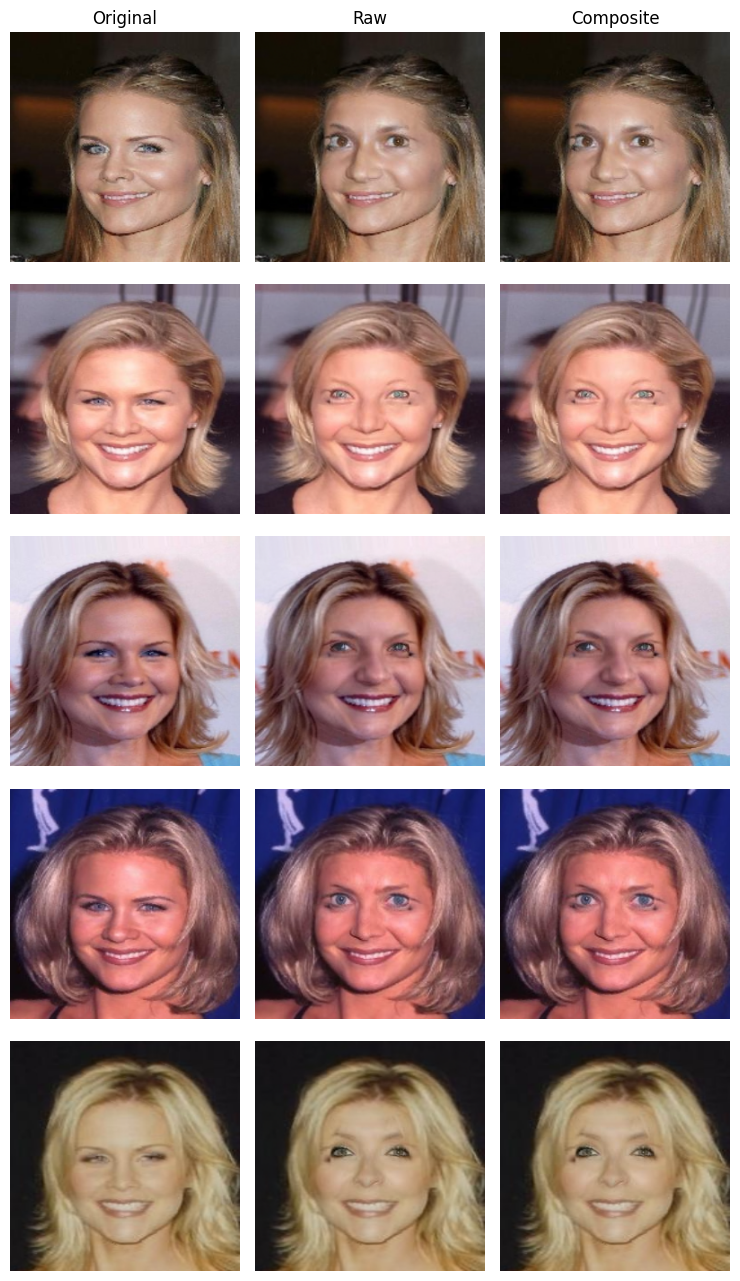

In [9]:
# Display saved baseline results (works after a previous full run, without re-sampling).
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

metrics_path = BASELINE_DIR / "per_image_metrics.csv"
if metrics_path.exists():
    df = pd.read_csv(metrics_path)
    cols = ["image", "nfe", "wall_time_s", "missing_psnr_db", "boundary_inner_psnr_db",
            "composite_full_psnr_db", "composite_full_ssim", "raw_known_mae"]
    display(df[[c for c in cols if c in df]].round(4))
    display(df[[c for c in cols[1:] if c in df]].describe().loc[["mean", "std"]].round(4))
    stems = [Path(p).stem for p in df["image"]][:5]
    fig, axes = plt.subplots(len(stems), 3, figsize=(7.5, 2.6 * len(stems)), squeeze=False)
    for r, stem in enumerate(stems):
        for c, kind in enumerate(["original", "raw", "composite"]):
            axes[r, c].imshow(Image.open(BASELINE_DIR / "images" / f"{stem}_{kind}.png"))
            axes[r, c].axis("off")
            if r == 0: axes[r, c].set_title(kind.capitalize())
    plt.tight_layout(); plt.show()
else:
    print("No saved baseline results at", metrics_path)